**Linear Regression**

Linear Regression is statistical model that was found in the field of statistics. It assumes that there is a linear relationship between the input variables and the output variables.

It is a linear equation where the input variables are denoted as x, and the output variable is denoted as y. It assumes that specified set of combination of the input variables 'x' will give a predicted output which is known as 'y'.

It has a one-scale factor which is denoted as 'B', and this is a coefficient within our equation, there is also an additional coefficient which is also denoted as B, and this will give our line a degree of freedom, this is called as bias or intercept.

To learn the linear regression algorithm our goal is to estimate the values of our coefficients which in the representation of our data. In machine learning, when we are talking about learning a model, we are saying we are training a math model in order for it to make predictions. In linear regression, what will be doing is estimating the values of our coefficient known as B0 and Bn, in order to minimize the difference between the actual and also the predicted values.

**The Algorithm**

I. **Develop the Gradient Function**
  1. Initialize the coefficient m_gradient and b_gradient as zero.
  2. Create a for loop that will run as many time as the give iterations.
  3. Call in the data points for the independent variable (X) and the dependent variable (Y).
  4. Update m_gradient and b_gradient by using the gradient function.
  5. Create the variables m_now and b_now that will have the new values, initialize this by multipling the current m_gradient and b_gradient by the learning rate.
  6. Return m_now and b_now

II. **Within the Global Function**
  1. Get the data.
  2. Create and initialize the variables m and b to 0. Establish the learning rate and the number of iterations.
  3. Toss those variables and the data into the gradient descent function.
  4. Get the data points of x and y.
  5. Receive the predicted values of y_pred
  5. Plot the data points of the original data.
  6. Plot the new predicted points.
  7. Calculate the mean square error.
  

**What's new in this version**

The original code is kept as it was. Small fixes are marked with `# FIX:` comments, and new sections are marked with ✨. Additions:

- A consistent, cleaner chart style
- Exploring the data before modelling (scatter, histograms, correlation)
- A loss curve showing the model learning over the iterations
- How the line moves during training, and the gradient-descent path on the error surface
- The effect of the learning rate
- R² (how much of the variation the model explains) alongside MSE, RMSE and MAE
- Residual plots to check the model's mistakes
- A check against the exact answer (normal equation) and scikit-learn
- A train/test split to test the model on unseen data
- Making a real prediction (e.g. 9.25 hours of study)

**Importing the Libraries**



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np   # ✨ added: used for the vectorised maths and metrics

# ✨ One consistent style for every chart in the notebook
NAVY, BLUE, ORANGE, GRAY = '#13294b', '#2d7fd3', '#e8743b', '#8a8f98'
plt.rcParams.update({
    'figure.figsize': (8, 5),
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#c9ced6',
    'axes.grid': True,
    'grid.color': '#e6e9ee',
    'grid.linewidth': 0.8,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelsize': 11,
    'axes.labelcolor': '#333a45',
    'xtick.color': '#5a6270',
    'ytick.color': '#5a6270',
    'legend.frameon': False,
    'font.size': 10.5,
})

**Receiving the Database**

In [2]:
# FIX: the original used 'score.csv' here and '/content/score.csv' later (Colab only).
# This finds the file in either place, so the notebook runs in Colab, Jupyter or VS Code.
import os
CSV_PATH = '/content/score.csv' if os.path.exists('/content/score.csv') else 'score.csv'

data = pd.read_csv(CSV_PATH)

In [3]:
display(data)

display(data['Hours'].min(), data['Hours'].max())

# ✨ Summary statistics and a missing-values check
display(data.describe().round(2))
print('Missing values per column:')
print(data.isnull().sum())

,Hours,Scores
0,2.5,21
1,5.1,47
2,3.2,27
3,8.5,75
4,3.5,30
5,1.5,20
6,9.2,88
7,5.5,60
8,8.3,81
9,2.7,25


np.float64(1.1)

np.float64(9.2)

,Hours,Scores
count,25.00,25.00
mean,5.01,51.48
std,2.53,25.29
min,1.10,17.00
25%,2.70,30.00
50%,4.80,47.00
75%,7.40,75.00
max,9.20,95.00


Missing values per column:
Hours     0
Scores    0
dtype: int64


✨ **Exploring the Data**

Before training anything, look at the data. If the points form a rough straight line, linear regression is a sensible choice.

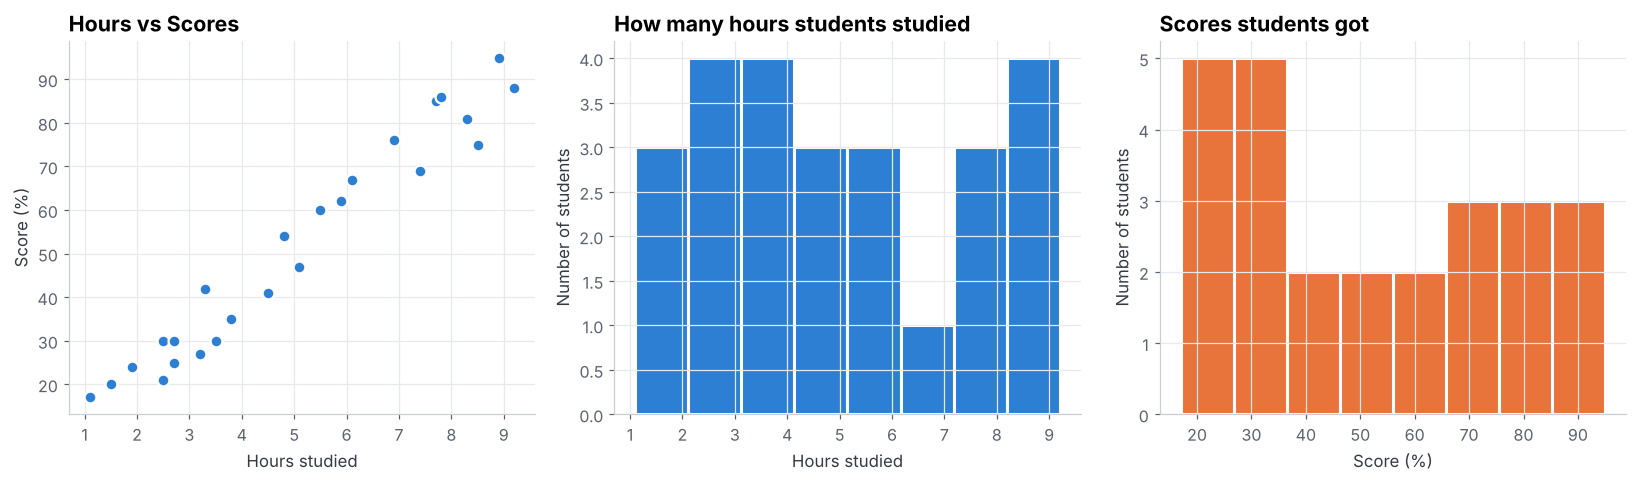

Correlation between Hours and Scores: 0.976
A value this close to +1 means a strong, positive, straight-line relationship.


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Relationship between hours and scores
axes[0].scatter(data['Hours'], data['Scores'], s=60, color=BLUE, edgecolor='white', linewidth=1.5, zorder=3)
axes[0].set_title('Hours vs Scores')
axes[0].set_xlabel('Hours studied')
axes[0].set_ylabel('Score (%)')

# 2. Distribution of hours
axes[1].hist(data['Hours'], bins=8, color=BLUE, edgecolor='white', linewidth=2)
axes[1].set_title('How many hours students studied')
axes[1].set_xlabel('Hours studied')
axes[1].set_ylabel('Number of students')

# 3. Distribution of scores
axes[2].hist(data['Scores'], bins=8, color=ORANGE, edgecolor='white', linewidth=2)
axes[2].set_title('Scores students got')
axes[2].set_xlabel('Score (%)')
axes[2].set_ylabel('Number of students')

plt.tight_layout()
plt.show()

corr = data['Hours'].corr(data['Scores'])
print(f'Correlation between Hours and Scores: {corr:.3f}')
print('A value this close to +1 means a strong, positive, straight-line relationship.')

**Establishing the Gradient Descent**

1. Initialize the values of each coeffient to 0.
2. Calculate the predicted output using the current coefficients.
3. Calculate the error of the gradient descent.
4. Use the learning rate as a scale factor as the coefficient are going in the direction that minimizes the errors.
5. Process is repeated until a local minimum is found.

In [5]:
def gradient_descent(m_now, b_now, points, L, iterations):
    n = len(points)

    for _ in range(iterations):
        m_gradient = 0
        b_gradient = 0

        for i in range(n):
            x = points.iloc[i].Hours
            y = points.iloc[i].Scores
            m_gradient += -(2/n) * x * (y - (m_now * x + b_now))
            b_gradient += -(2/n) * (y - (m_now * x + b_now))

        m_now -= m_gradient * L
        b_now -= b_gradient * L

    return m_now, b_now


✨ **Gradient Descent with History**

The same algorithm as above, written with NumPy arrays instead of a Python loop over rows (much faster), and it also **records** the error, `m` and `b` at every iteration so we can watch the model learn.

In [6]:
def gradient_descent_history(m_now, b_now, x, y, L, iterations):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    history = {'m': [], 'b': [], 'mse': []}

    for _ in range(iterations):
        error = y - (m_now * x + b_now)
        history['m'].append(m_now)
        history['b'].append(b_now)
        history['mse'].append(np.mean(error ** 2))

        m_gradient = -(2/n) * np.sum(x * error)
        b_gradient = -(2/n) * np.sum(error)

        m_now -= m_gradient * L
        b_now -= b_gradient * L

    return m_now, b_now, history

9.778905988234964 2.464452271476101
0    26.911717
1    52.336873
2    33.756951
3    85.585153
4    36.690623
Name: Hours, dtype: float64


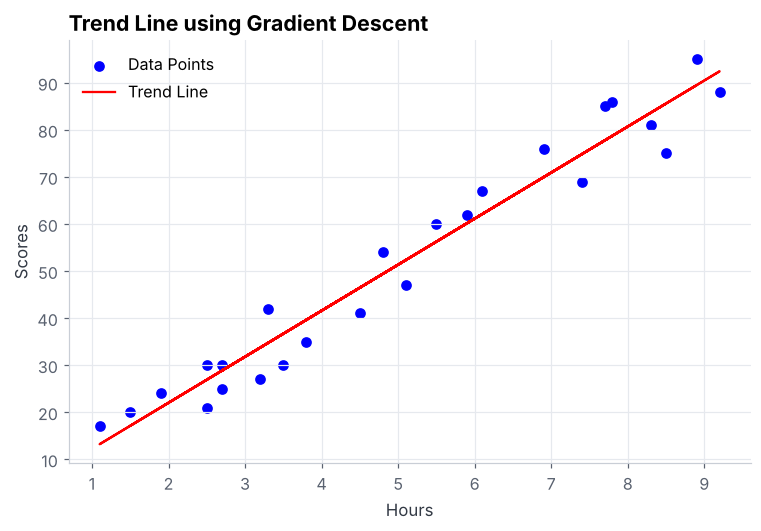

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sample data points
points = pd.read_csv(CSV_PATH)  # FIX: works outside Colab too

# Initial parameters
m_now = 0
b_now = 0
L = 0.01  # Learning rate
iterations = 1000  # Number of iterations

# Perform gradient descent
m, b = gradient_descent(m_now, b_now, points, L, iterations)
print(m, b)

# Predicted values
X = points['Hours']
Y = points['Scores']
Y_pred = m * X + b
print(Y_pred.head())  # FIX: .info() only described the Series and printed 'None'

# Plotting the data points
plt.scatter(X, Y, color='blue', label='Data Points')

# Plotting the trend line
plt.plot(X, Y_pred, color='red', label='Trend Line')

# Adding labels and title
plt.xlabel('Hours')
plt.ylabel('Scores')
plt.title('Trend Line using Gradient Descent')
plt.legend()

# Showing the plot
plt.show()


✨ **A Better Trend-Line Chart**

The same result, but easier to read: the line's equation is shown, and the dashed lines (residuals) show how far each real score is from the prediction.

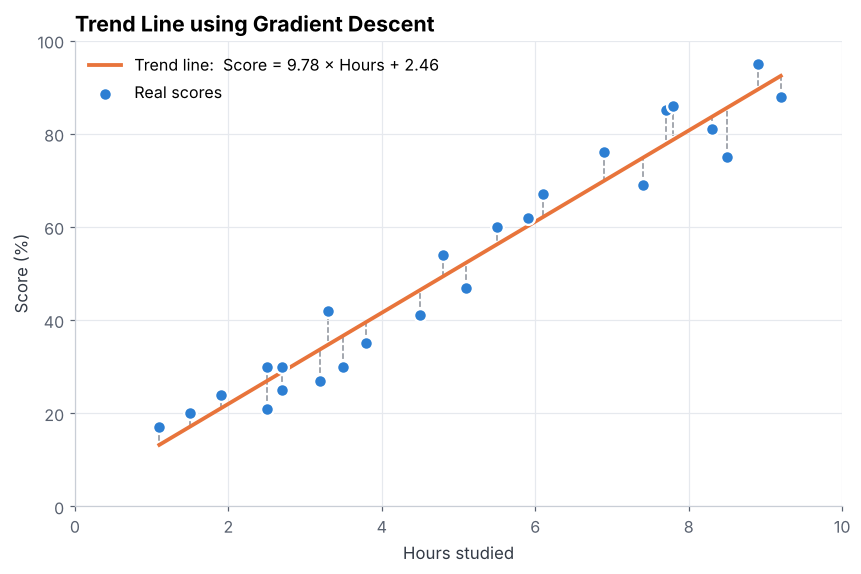

Every extra hour of study adds about 9.78 points to the score.


In [8]:
order = np.argsort(X.values)
fig, ax = plt.subplots(figsize=(9, 5.5))

# Residual lines: the gap between each real score and the prediction
for xi, yi, ypi in zip(X, Y, Y_pred):
    ax.plot([xi, xi], [yi, ypi], color=GRAY, linestyle='--', linewidth=1, zorder=1)

ax.plot(X.values[order], Y_pred.values[order], color=ORANGE, linewidth=2.5,
        label=f'Trend line:  Score = {m:.2f} × Hours + {b:.2f}', zorder=2)
ax.scatter(X, Y, s=70, color=BLUE, edgecolor='white', linewidth=1.5, label='Real scores', zorder=3)

ax.set_xlabel('Hours studied')
ax.set_ylabel('Score (%)')
ax.set_title('Trend Line using Gradient Descent')
ax.legend(loc='upper left')
ax.set_xlim(0, 10)
ax.set_ylim(0, 100)
plt.show()

print(f'Every extra hour of study adds about {m:.2f} points to the score.')

✨ **Watching the Model Learn**

The **loss curve** shows the mean squared error at each iteration. It drops quickly at first and then flattens out: that flattening means the model has converged (found the bottom of the error valley).

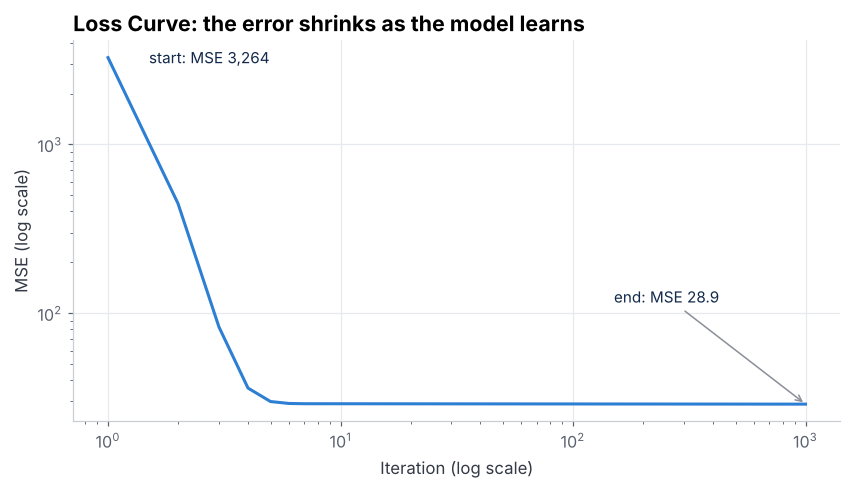

Vectorised version gives m = 9.7789, b = 2.4645 (same as the loop version: m = 9.7789, b = 2.4645)


In [9]:
m_h, b_h, history = gradient_descent_history(0, 0, X, Y, L=0.01, iterations=1000)

fig, ax = plt.subplots(figsize=(9, 4.5))
iters = np.arange(1, len(history['mse']) + 1)
ax.plot(iters, history['mse'], color=BLUE, linewidth=2)
ax.set_xscale('log')   # log scales so the fast early drop is visible
ax.set_yscale('log')
ax.set_xlabel('Iteration (log scale)')
ax.set_ylabel('MSE (log scale)')
ax.set_title('Loss Curve: the error shrinks as the model learns')
ax.annotate(f"start: MSE {history['mse'][0]:,.0f}", (1, history['mse'][0]), xytext=(1.5, history['mse'][0]),
            fontsize=10, color=NAVY, va='center')
ax.annotate(f"end: MSE {history['mse'][-1]:.1f}", (1000, history['mse'][-1]), xytext=(150, history['mse'][-1]*4),
            fontsize=10, color=NAVY, arrowprops=dict(arrowstyle='->', color=GRAY))
plt.show()

print(f'Vectorised version gives m = {m_h:.4f}, b = {b_h:.4f} (same as the loop version: m = {m:.4f}, b = {b:.4f})')

✨ **How the Line Moves During Training**

Each line is the model at a different iteration. It starts flat (m = 0, b = 0) and quickly swings up to fit the data.

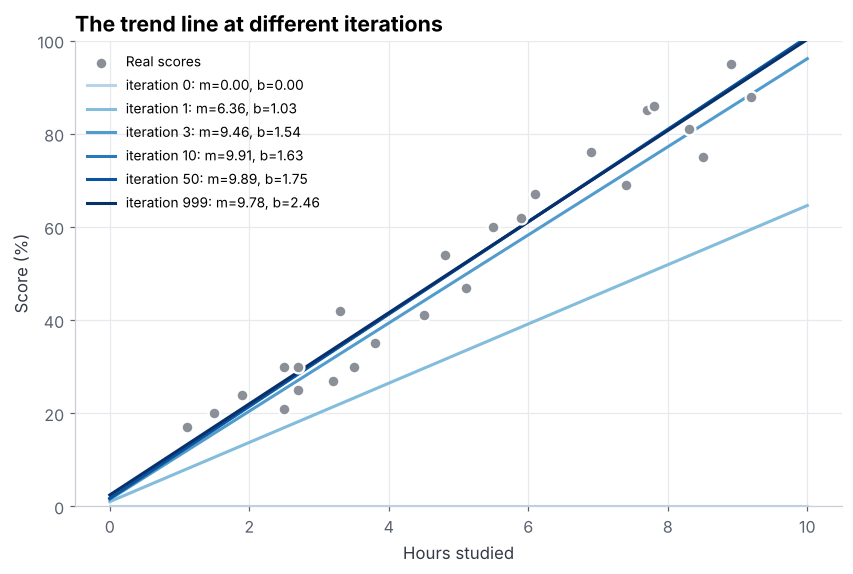

In [10]:
snapshots = [0, 1, 3, 10, 50, 999]
shades = plt.cm.Blues(np.linspace(0.3, 1, len(snapshots)))
x_line = np.linspace(0, 10, 50)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(X, Y, s=60, color=GRAY, edgecolor='white', linewidth=1.5, zorder=3, label='Real scores')
for it, c in zip(snapshots, shades):
    mi, bi = history['m'][it], history['b'][it]
    ax.plot(x_line, mi * x_line + bi, color=c, linewidth=2, label=f'iteration {it}: m={mi:.2f}, b={bi:.2f}')
ax.set_xlabel('Hours studied')
ax.set_ylabel('Score (%)')
ax.set_title('The trend line at different iterations')
ax.set_ylim(0, 100)
ax.legend(loc='upper left', fontsize=9)
plt.show()

✨ **The Error Surface**

Every possible pair of (m, b) has an MSE. Plotting them makes a "valley". Gradient descent starts at (0, 0) and walks downhill step by step (orange path) until it reaches the bottom (the star).

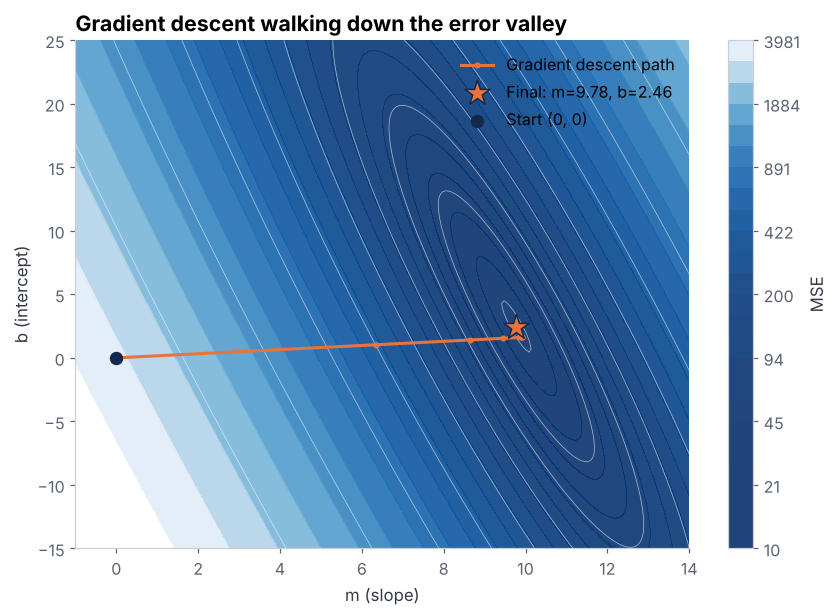

In [11]:
m_grid = np.linspace(-1, 14, 200)
b_grid = np.linspace(-15, 25, 200)
M, B = np.meshgrid(m_grid, b_grid)
x_arr, y_arr = X.values, Y.values
Z = np.mean((y_arr[None, None, :] - (M[..., None] * x_arr + B[..., None])) ** 2, axis=2)

fig, ax = plt.subplots(figsize=(9, 6))
cs = ax.contourf(M, B, Z, levels=np.logspace(1, 3.6, 25), cmap='Blues_r', alpha=0.9)
ax.contour(M, B, Z, levels=np.logspace(1, 3.6, 12), colors='white', linewidths=0.5, alpha=0.6)
ax.plot(history['m'], history['b'], color=ORANGE, linewidth=2, marker='o', markersize=3,
        markevery=[0, 1, 2, 3, 5, 10, 25, 50, 100, 300, 999], label='Gradient descent path')
ax.scatter([m], [b], marker='*', s=300, color=ORANGE, edgecolor=NAVY, zorder=5, label=f'Final: m={m:.2f}, b={b:.2f}')
ax.scatter([0], [0], s=60, color=NAVY, zorder=5, label='Start (0, 0)')
ax.set_xlabel('m (slope)')
ax.set_ylabel('b (intercept)')
ax.set_title('Gradient descent walking down the error valley')
ax.grid(False)
ax.legend(loc='upper right')
fig.colorbar(cs, ax=ax, label='MSE', format='%.0f')
plt.show()

✨ **Choosing the Learning Rate**

The learning rate `L` is the size of each step. Too small and learning is slow; too large and the steps overshoot the valley and the error explodes.

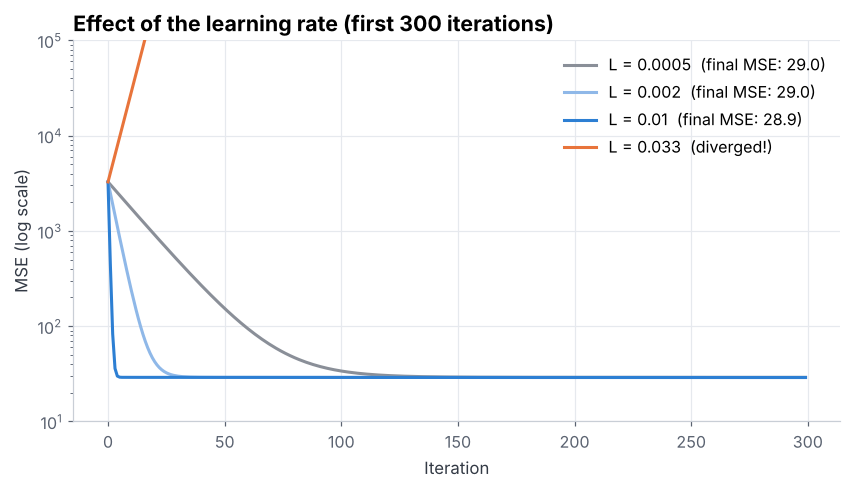

Largest learning rate that still converges for this data: about 0.0312
L = 0.033 is just above that, so each step overshoots and the error grows instead of shrinking.


In [12]:
rates = {0.0005: GRAY, 0.002: '#8fb8e8', 0.01: BLUE, 0.033: ORANGE}

fig, ax = plt.subplots(figsize=(9, 4.5))
for rate, color in rates.items():
    _, _, h = gradient_descent_history(0, 0, X, Y, L=rate, iterations=300)
    final = h['mse'][-1]
    status = 'diverged!' if final > h['mse'][0] else f'final MSE: {final:,.1f}'
    ax.plot(h['mse'], color=color, linewidth=2, label=f'L = {rate}  ({status})')
ax.set_yscale('log')
ax.set_ylim(10, 1e5)
ax.set_xlabel('Iteration')
ax.set_ylabel('MSE (log scale)')
ax.set_title('Effect of the learning rate (first 300 iterations)')
ax.legend()
plt.show()

# The largest safe learning rate depends on the data: L must be below 2 / (largest eigenvalue of the Hessian)
x_arr = X.values
H = (2/len(x_arr)) * np.array([[np.sum(x_arr**2), np.sum(x_arr)], [np.sum(x_arr), len(x_arr)]])
print(f'Largest learning rate that still converges for this data: about {2/np.linalg.eigvalsh(H).max():.4f}')
print('L = 0.033 is just above that, so each step overshoots and the error grows instead of shrinking.')

**Mean Squared Error**

*Mean squared error* is metric that is used to determine how far the predicted value is from the true underlying values. If the mean square error's value is high than there isn't much accuracy in our model, and the predicted and the true values are far from each other. It measures the average squared difference between the predicted values and the true values.

In [13]:
import numpy as np
def mean_squared_error(y_pred, Y):
    return np.mean((y_pred - Y) ** 2)

mse = mean_squared_error(Y_pred, Y)
print(mse)

rsme = np.sqrt(mse)
print(rsme)

28.882802906830015
5.374272314167753


In [14]:
# If y is a NumPy array or pandas Series
print(Y.min())    # minimum value
print(Y.max())    # maximum value
print(Y.mean())   # mean value
print(Y.std())    # standard deviation

y_mean = Y.mean()

17
95
51.48
25.28688724747802


**Coefficient of Variation (CV) of the RMSE**

The RMSE as a percentage of the average score. Around 10% means the typical error is about a tenth of the average score.

In [15]:
def cv(rsme,y_mean):
  return (rsme/y_mean)*100

print(cv(rsme, y_mean))

10.43953440980527


In [16]:
def mean_absolute_error(y_pred, Y):
  return np.mean(np.abs(y_pred - Y))  # FIX: the second np.mean was not needed

print(mean_absolute_error(Y_pred, Y))

4.974131435140619


✨ **R² (Coefficient of Determination)**

R² answers: *how much of the variation in scores does the model explain?* 1.0 is perfect, 0 means no better than always guessing the average score.

R² = 1 − (sum of squared errors ÷ total sum of squares)

In [17]:
def r_squared(y_pred, Y):
    ss_res = np.sum((Y - y_pred) ** 2)
    ss_tot = np.sum((Y - Y.mean()) ** 2)
    return 1 - ss_res / ss_tot

r2 = r_squared(Y_pred, Y)
print(f'R² = {r2:.4f}  ->  hours studied explain about {r2*100:.1f}% of the variation in scores')

R² = 0.9529  ->  hours studied explain about 95.3% of the variation in scores


✨ **Checking the Mistakes (Residual Analysis)**

A residual is *real score − predicted score*. For a good linear model the residuals should be scattered randomly around 0, with no pattern.

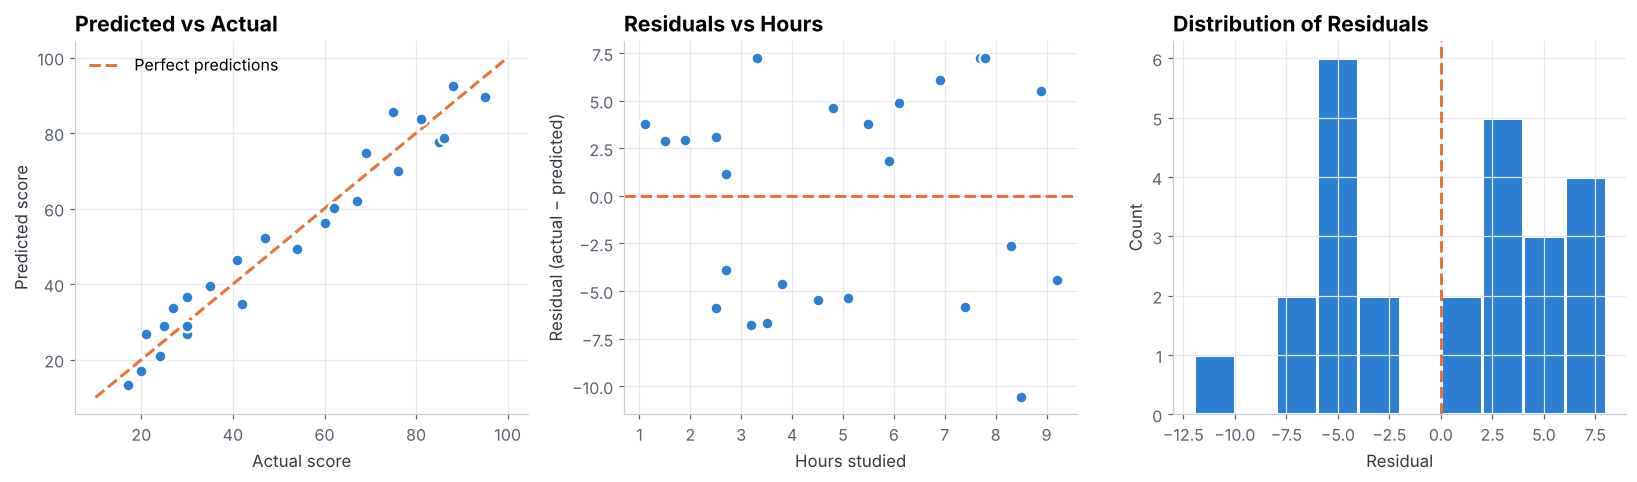

Mean residual: 0.004 (close to 0 = no systematic over- or under-prediction)
Largest miss: 10.59 points


In [18]:
residuals = Y - Y_pred
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Predicted vs actual
axes[0].scatter(Y, Y_pred, s=60, color=BLUE, edgecolor='white', linewidth=1.5, zorder=3)
axes[0].plot([10, 100], [10, 100], color=ORANGE, linewidth=2, linestyle='--', label='Perfect predictions')
axes[0].set_xlabel('Actual score')
axes[0].set_ylabel('Predicted score')
axes[0].set_title('Predicted vs Actual')
axes[0].legend(loc='upper left')

# 2. Residuals vs hours
axes[1].axhline(0, color=ORANGE, linewidth=2, linestyle='--')
axes[1].scatter(X, residuals, s=60, color=BLUE, edgecolor='white', linewidth=1.5, zorder=3)
axes[1].set_xlabel('Hours studied')
axes[1].set_ylabel('Residual (actual − predicted)')
axes[1].set_title('Residuals vs Hours')

# 3. Distribution of residuals
axes[2].hist(residuals, bins=np.arange(-12, 10, 2), color=BLUE, edgecolor='white', linewidth=2)
axes[2].axvline(0, color=ORANGE, linewidth=2, linestyle='--')
axes[2].set_xlabel('Residual')
axes[2].set_ylabel('Count')
axes[2].set_title('Distribution of Residuals')

plt.tight_layout()
plt.show()
print(f'Mean residual: {residuals.mean():.3f} (close to 0 = no systematic over- or under-prediction)')
print(f'Largest miss: {residuals.abs().max():.2f} points')

✨ **Checking Our Answer**

Simple linear regression also has an exact formula (the *normal equation* / ordinary least squares). If gradient descent worked, it should land almost on the same m and b. We also compare with scikit-learn's `LinearRegression`.

In [19]:
from sklearn.linear_model import LinearRegression

# Exact formula
m_exact = np.sum((X - X.mean()) * (Y - Y.mean())) / np.sum((X - X.mean()) ** 2)
b_exact = Y.mean() - m_exact * X.mean()

# scikit-learn
sk = LinearRegression().fit(points[['Hours']], Y)

comparison = pd.DataFrame({
    'm (slope)':     [m, m_exact, sk.coef_[0]],
    'b (intercept)': [b, b_exact, sk.intercept_],
    'MSE': [mean_squared_error(m*X + b, Y),
            mean_squared_error(m_exact*X + b_exact, Y),
            mean_squared_error(sk.predict(points[['Hours']]), Y)],
}, index=['Our gradient descent', 'Exact formula (OLS)', 'scikit-learn'])
display(comparison.round(4))

,m (slope),b (intercept),MSE
Our gradient descent,9.7789,2.4645,28.8828
Exact formula (OLS),9.7758,2.4837,28.8827
scikit-learn,9.7758,2.4837,28.8827


✨ **Testing on Unseen Data (Train/Test Split)**

So far we measured error on the same data we trained on. A fairer test: train on 80% of students and test on the 20% the model has never seen.

,RMSE,MAE,R²
Train (20 students),5.608,5.223,0.949
Test (5 students),4.351,3.922,0.968


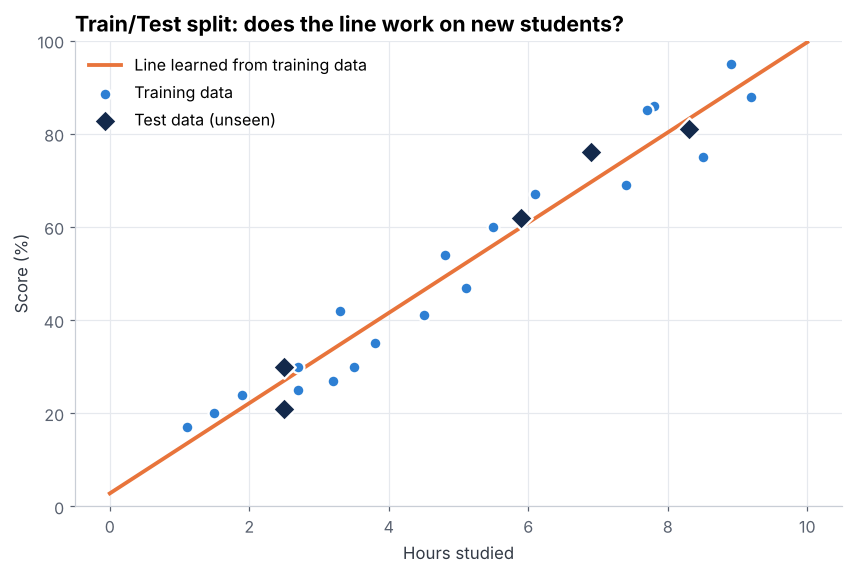

,Hours,Actual,Predicted,Error
8,8.3,81,83.2,-2.2
16,2.5,30,27.0,3.0
0,2.5,21,27.0,-6.0
23,6.9,76,69.6,6.4
11,5.9,62,60.0,2.0


In [20]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(points, test_size=0.2, random_state=42)
m_tr, b_tr, _ = gradient_descent_history(0, 0, train['Hours'], train['Scores'], L=0.01, iterations=1000)

pred_train = m_tr * train['Hours'] + b_tr
pred_test  = m_tr * test['Hours'] + b_tr

results = pd.DataFrame({
    'RMSE': [np.sqrt(mean_squared_error(pred_train, train['Scores'])), np.sqrt(mean_squared_error(pred_test, test['Scores']))],
    'MAE':  [mean_absolute_error(pred_train, train['Scores']), mean_absolute_error(pred_test, test['Scores'])],
    'R²':   [r_squared(pred_train, train['Scores']), r_squared(pred_test, test['Scores'])],
}, index=[f'Train ({len(train)} students)', f'Test ({len(test)} students)'])
display(results.round(3))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(x_line, m_tr * x_line + b_tr, color=ORANGE, linewidth=2.5, label=f'Line learned from training data')
ax.scatter(train['Hours'], train['Scores'], s=60, color=BLUE, edgecolor='white', linewidth=1.5, zorder=3, label='Training data')
ax.scatter(test['Hours'], test['Scores'], s=110, color=NAVY, marker='D', edgecolor='white', linewidth=1.5, zorder=4, label='Test data (unseen)')
ax.set_xlabel('Hours studied')
ax.set_ylabel('Score (%)')
ax.set_title('Train/Test split: does the line work on new students?')
ax.set_ylim(0, 100)
ax.legend(loc='upper left')
plt.show()

display(pd.DataFrame({'Hours': test['Hours'], 'Actual': test['Scores'],
                      'Predicted': pred_test.round(1), 'Error': (test['Scores'] - pred_test).round(1)}))

✨ **Making a Prediction**

The whole point of the model: given a new student's study hours, predict their score.

In [21]:
def predict_score(hours):
    return m * hours + b

for h in [2, 5, 9.25]:
    print(f'A student who studies {h} hours is predicted to score {predict_score(h):.1f}%')

A student who studies 2 hours is predicted to score 22.0%
A student who studies 5 hours is predicted to score 51.4%
A student who studies 9.25 hours is predicted to score 92.9%


✨ **Summary**

In [22]:
summary = pd.DataFrame({
    'Value': [f'{m:.3f}', f'{b:.3f}', f'{mse:.2f}', f'{rsme:.2f}', f'{mean_absolute_error(Y_pred, Y):.2f}',
              f'{cv(rsme, y_mean):.1f}%', f'{r2:.3f}', f'{predict_score(9.25):.1f}'],
    'Meaning': ['Points gained per extra hour of study',
                'Predicted score with 0 hours of study',
                'Average squared error',
                'Typical error, in score points',
                'Average absolute error, in score points',
                'RMSE as a % of the average score',
                'Share of score variation explained by hours',
                'Predicted score for 9.25 hours'],
}, index=['Slope (m)', 'Intercept (b)', 'MSE', 'RMSE', 'MAE', 'CV of RMSE', 'R²', 'Prediction @ 9.25h'])
display(summary)

,Value,Meaning
Slope (m),9.779,Points gained per extra hour of study
Intercept (b),2.464,Predicted score with 0 hours of study
MSE,28.88,Average squared error
RMSE,5.37,"Typical error, in score points"
MAE,4.97,"Average absolute error, in score points"
CV of RMSE,10.4%,RMSE as a % of the average score
R²,0.953,Share of score variation explained by hours
Prediction @ 9.25h,92.9,Predicted score for 9.25 hours
